<a href="https://colab.research.google.com/github/at-vaishnavi/AutoNovaX/blob/main/Online_Food_Delivery_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Online Food Delivery – PySpark Case Study
The main objective of this project is to analyse the Online Food Delivery dataset using PySpark and understand the order details and sales performance.

The specific objectives are:
1. To load the dataset into a PySpark DataFrame.
2. To understand the structure and details of the dataset.
3. To perform data operations such as filtering, sorting, grouping and selecting records.
4. To calculate total sales and order values.
5. To identify popular food items and analyse restaurant performance.
6. To analyse delivery time and customer ratings.
7. To perform queries using Spark SQL.
8. To present the results using bar charts.

In [ ]:
# Install the PySpark library.
!pip -q install pyspark
print("PySpark installed successfully.")

PySpark installed successfully.


In [ ]:
# Import the required libraries for data processing and visualization.
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, avg, min, max, count, desc, asc, round, when
import matplotlib.pyplot as plt
import os

In [ ]:
# Create a Spark session to perform operations using PySpark.
spark = (SparkSession.builder
         .appName("OnlineFoodDeliveryCaseStudy")
         .master("local[*]")
         .getOrCreate())

print("Spark Session Created Successfully!")

Spark Session Created Successfully!


In [ ]:
# Create the sample food delivery dataset and save it as a CSV file.
food_data = """order_id,customer,restaurant,item,quantity,item_price,delivery_time,rating,city
O001,Aarav,Food Corner,Burger,2,8.50,28,5,Bengaluru
O002,Diya,Pizza Hub,Pizza,1,15.00,35,4,Mysuru
O003,Rohan,Food Corner,French Fries,3,4.00,22,4,Bengaluru
O004,Ananya,South Kitchen,Dosa,2,5.50,25,5,Chennai
O005,Vikram,Pizza Hub,Pizza,2,15.00,40,3,Bengaluru
O006,Meera,South Kitchen,Idli,4,3.00,20,5,Chennai
O007,Arjun,Spice House,Biryani,2,12.50,45,4,Hyderabad
O008,Isha,Food Corner,Burger,1,8.50,30,4,Mysuru
O009,Kabir,Spice House,Biryani,1,12.50,38,5,Hyderabad
O010,Saanvi,South Kitchen,Dosa,3,5.50,27,4,Bengaluru
O011,Rahul,Pizza Hub,Pasta,2,10.00,32,5,Chennai
O012,Priya,Spice House,Noodles,2,7.50,36,3,Hyderabad
O013,Neha,Food Corner,Sandwich,2,6.00,24,4,Bengaluru
O014,Aditya,Pizza Hub,Pizza,1,15.00,29,5,Mysuru
O015,Kavya,South Kitchen,Idli,3,3.00,18,4,Chennai
"""

with open("/content/food_delivery_orders.csv", "w") as file:
    file.write(food_data)

print("Dataset created successfully.")
print("File location: /content/food_delivery_orders.csv")

Dataset created successfully.
File location: /content/food_delivery_orders.csv


In [ ]:
# Load the CSV file into a PySpark DataFrame.
df = spark.read.csv(
    "/content/food_delivery_orders.csv",
    header=True,
    inferSchema=True
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# Display all records from the dataset.
df.show(truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+
|O001    |Aarav   |Food Corner  |Burger      |2       |8.5       |28           |5     |Bengaluru|
|O002    |Diya    |Pizza Hub    |Pizza       |1       |15.0      |35           |4     |Mysuru   |
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|
|O004    |Ananya  |South Kitchen|Dosa        |2       |5.5       |25           |5     |Chennai  |
|O005    |Vikram  |Pizza Hub    |Pizza       |2       |15.0      |40           |3     |Bengaluru|
|O006    |Meera   |South Kitchen|Idli        |4       |3.0       |20           |5     |Chennai  |
|O007    |Arjun   |Spice House  |Biryani     |2       |12.5      |45           |4     |Hyderabad|
|O008    |Isha    |F

In [ ]:
# Display the first five records of the dataset.
df.show(5, truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+
|O001    |Aarav   |Food Corner  |Burger      |2       |8.5       |28           |5     |Bengaluru|
|O002    |Diya    |Pizza Hub    |Pizza       |1       |15.0      |35           |4     |Mysuru   |
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|
|O004    |Ananya  |South Kitchen|Dosa        |2       |5.5       |25           |5     |Chennai  |
|O005    |Vikram  |Pizza Hub    |Pizza       |2       |15.0      |40           |3     |Bengaluru|
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+
only showing top 5 rows


In [ ]:
# Find the total number of rows and columns in the dataset.
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

Total Rows: 15
Total Columns: 9


In [ ]:
# Display the column names and their respective data types.
print("Column Names:", df.columns)
df.printSchema()

Column Names: ['order_id', 'customer', 'restaurant', 'item', 'quantity', 'item_price', 'delivery_time', 'rating', 'city']
root
 |-- order_id: string (nullable = true)
 |-- customer: string (nullable = true)
 |-- restaurant: string (nullable = true)
 |-- item: string (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- item_price: double (nullable = true)
 |-- delivery_time: integer (nullable = true)
 |-- rating: integer (nullable = true)
 |-- city: string (nullable = true)



# Part A – DataFrame Operations

In [ ]:
# Select and display the required columns from the dataset.
df.select("order_id", "customer", "restaurant", "item").show(truncate=False)

+--------+--------+-------------+------------+
|order_id|customer|restaurant   |item        |
+--------+--------+-------------+------------+
|O001    |Aarav   |Food Corner  |Burger      |
|O002    |Diya    |Pizza Hub    |Pizza       |
|O003    |Rohan   |Food Corner  |French Fries|
|O004    |Ananya  |South Kitchen|Dosa        |
|O005    |Vikram  |Pizza Hub    |Pizza       |
|O006    |Meera   |South Kitchen|Idli        |
|O007    |Arjun   |Spice House  |Biryani     |
|O008    |Isha    |Food Corner  |Burger      |
|O009    |Kabir   |Spice House  |Biryani     |
|O010    |Saanvi  |South Kitchen|Dosa        |
|O011    |Rahul   |Pizza Hub    |Pasta       |
|O012    |Priya   |Spice House  |Noodles     |
|O013    |Neha    |Food Corner  |Sandwich    |
|O014    |Aditya  |Pizza Hub    |Pizza       |
|O015    |Kavya   |South Kitchen|Idli        |
+--------+--------+-------------+------------+



In [ ]:
# Display only the orders placed in Bengaluru.
df.filter(col("city") == "Bengaluru").show(truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+
|O001    |Aarav   |Food Corner  |Burger      |2       |8.5       |28           |5     |Bengaluru|
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|
|O005    |Vikram  |Pizza Hub    |Pizza       |2       |15.0      |40           |3     |Bengaluru|
|O010    |Saanvi  |South Kitchen|Dosa        |3       |5.5       |27           |4     |Bengaluru|
|O013    |Neha    |Food Corner  |Sandwich    |2       |6.0       |24           |4     |Bengaluru|
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+



In [ ]:
# Display orders that received a rating of 5.
df.filter(col("rating") == 5).show(truncate=False)

+--------+--------+-------------+-------+--------+----------+-------------+------+---------+
|order_id|customer|restaurant   |item   |quantity|item_price|delivery_time|rating|city     |
+--------+--------+-------------+-------+--------+----------+-------------+------+---------+
|O001    |Aarav   |Food Corner  |Burger |2       |8.5       |28           |5     |Bengaluru|
|O004    |Ananya  |South Kitchen|Dosa   |2       |5.5       |25           |5     |Chennai  |
|O006    |Meera   |South Kitchen|Idli   |4       |3.0       |20           |5     |Chennai  |
|O009    |Kabir   |Spice House  |Biryani|1       |12.5      |38           |5     |Hyderabad|
|O011    |Rahul   |Pizza Hub    |Pasta  |2       |10.0      |32           |5     |Chennai  |
|O014    |Aditya  |Pizza Hub    |Pizza  |1       |15.0      |29           |5     |Mysuru   |
+--------+--------+-------------+-------+--------+----------+-------------+------+---------+



In [ ]:
# Calculate the total order value using quantity and item price.
df = df.withColumn("total_value", round(col("quantity") * col("item_price"), 2))
df.show(truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|O001    |Aarav   |Food Corner  |Burger      |2       |8.5       |28           |5     |Bengaluru|17.0       |
|O002    |Diya    |Pizza Hub    |Pizza       |1       |15.0      |35           |4     |Mysuru   |15.0       |
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|12.0       |
|O004    |Ananya  |South Kitchen|Dosa        |2       |5.5       |25           |5     |Chennai  |11.0       |
|O005    |Vikram  |Pizza Hub    |Pizza       |2       |15.0      |40           |3     |Bengaluru|30.0       |
|O006    |Meera   |South Kitchen|Idli        |4       |3.0       |20           |5     |Chennai  |12.0       |
|O007    |

In [ ]:
# Calculate the total sales value of all orders.
df.select(round(sum("total_value"), 2).alias("total_sales")).show()

+-----------+
|total_sales|
+-----------+
|      230.5|
+-----------+



In [ ]:
# Calculate the total sales value of all orders.
df.select(
    min("total_value").alias("minimum_order_value"),
    max("total_value").alias("maximum_order_value"),
    round(avg("total_value"), 2).alias("average_order_value")
).show()

+-------------------+-------------------+-------------------+
|minimum_order_value|maximum_order_value|average_order_value|
+-------------------+-------------------+-------------------+
|                8.5|               30.0|              15.37|
+-------------------+-------------------+-------------------+



In [ ]:
# Calculate the minimum, maximum and average order value.
df.groupBy("restaurant").count().orderBy(desc("count")).show()

+-------------+-----+
|   restaurant|count|
+-------------+-----+
|  Food Corner|    4|
|    Pizza Hub|    4|
|South Kitchen|    4|
|  Spice House|    3|
+-------------+-----+



In [ ]:
# Calculate the total quantity ordered for each food item.
df.groupBy("item").agg(
    sum("quantity").alias("total_quantity")
).orderBy(desc("total_quantity")).show()

+------------+--------------+
|        item|total_quantity|
+------------+--------------+
|        Idli|             7|
|        Dosa|             5|
|       Pizza|             4|
|     Biryani|             3|
|      Burger|             3|
|French Fries|             3|
|    Sandwich|             2|
|       Pasta|             2|
|     Noodles|             2|
+------------+--------------+



In [ ]:
# Calculate the total sales generated by each restaurant.
df.groupBy("restaurant").agg(
    round(sum("total_value"), 2).alias("total_sales")
).orderBy(desc("total_sales")).show()

+-------------+-----------+
|   restaurant|total_sales|
+-------------+-----------+
|    Pizza Hub|       80.0|
|  Spice House|       52.5|
|  Food Corner|       49.5|
|South Kitchen|       48.5|
+-------------+-----------+



In [ ]:
# Calculate the average delivery time for each restaurant.
df.groupBy("restaurant").agg(
    round(avg("delivery_time"), 2).alias("average_delivery_time")
).orderBy(asc("average_delivery_time")).show()

+-------------+---------------------+
|   restaurant|average_delivery_time|
+-------------+---------------------+
|South Kitchen|                 22.5|
|  Food Corner|                 26.0|
|    Pizza Hub|                 34.0|
|  Spice House|                39.67|
+-------------+---------------------+



In [ ]:
# Calculate the average customer rating for each restaurant.
df.groupBy("restaurant").agg(
    round(avg("rating"), 2).alias("average_rating")
).orderBy(desc("average_rating")).show()

+-------------+--------------+
|   restaurant|average_rating|
+-------------+--------------+
|South Kitchen|           4.5|
|  Food Corner|          4.25|
|    Pizza Hub|          4.25|
|  Spice House|           4.0|
+-------------+--------------+



In [ ]:
# Sort the orders based on delivery time in ascending order.
df.orderBy(asc("delivery_time")).show(truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|O015    |Kavya   |South Kitchen|Idli        |3       |3.0       |18           |4     |Chennai  |9.0        |
|O006    |Meera   |South Kitchen|Idli        |4       |3.0       |20           |5     |Chennai  |12.0       |
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|12.0       |
|O013    |Neha    |Food Corner  |Sandwich    |2       |6.0       |24           |4     |Bengaluru|12.0       |
|O004    |Ananya  |South Kitchen|Dosa        |2       |5.5       |25           |5     |Chennai  |11.0       |
|O010    |Saanvi  |South Kitchen|Dosa        |3       |5.5       |27           |4     |Bengaluru|16.5       |
|O001    |

In [ ]:
# Display orders having a total value greater than 20.
df.filter(col("total_value") > 20).show(truncate=False)

+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant |item   |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+
|O005    |Vikram  |Pizza Hub  |Pizza  |2       |15.0      |40           |3     |Bengaluru|30.0       |
|O007    |Arjun   |Spice House|Biryani|2       |12.5      |45           |4     |Hyderabad|25.0       |
+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+



# Part B – Spark SQL Operations


In [ ]:
# Create a temporary SQL view from the DataFrame.
df.createOrReplaceTempView("food_orders")
print("Temporary view created successfully.")

Temporary view created successfully.


In [ ]:
# Retrieve all records from the temporary SQL view.
spark.sql("SELECT * FROM food_orders").show(truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|O001    |Aarav   |Food Corner  |Burger      |2       |8.5       |28           |5     |Bengaluru|17.0       |
|O002    |Diya    |Pizza Hub    |Pizza       |1       |15.0      |35           |4     |Mysuru   |15.0       |
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|12.0       |
|O004    |Ananya  |South Kitchen|Dosa        |2       |5.5       |25           |5     |Chennai  |11.0       |
|O005    |Vikram  |Pizza Hub    |Pizza       |2       |15.0      |40           |3     |Bengaluru|30.0       |
|O006    |Meera   |South Kitchen|Idli        |4       |3.0       |20           |5     |Chennai  |12.0       |
|O007    |

In [ ]:
# Count the total number of orders using an SQL query.
spark.sql("""SELECT COUNT(*) AS total_orders
FROM food_orders""").show()

+------------+
|total_orders|
+------------+
|          15|
+------------+



In [ ]:
# Find the number of orders placed at each restaurant using SQL.
spark.sql("""SELECT restaurant, COUNT(*) AS total_orders
FROM food_orders
GROUP BY restaurant
ORDER BY total_orders DESC""").show()

+-------------+------------+
|   restaurant|total_orders|
+-------------+------------+
|  Food Corner|           4|
|    Pizza Hub|           4|
|South Kitchen|           4|
|  Spice House|           3|
+-------------+------------+



In [ ]:
# Calculate the total sales generated by each restaurant using SQL.
spark.sql("""SELECT restaurant, ROUND(SUM(total_value), 2) AS total_sales
FROM food_orders
GROUP BY restaurant
ORDER BY total_sales DESC""").show()

+-------------+-----------+
|   restaurant|total_sales|
+-------------+-----------+
|    Pizza Hub|       80.0|
|  Spice House|       52.5|
|  Food Corner|       49.5|
|South Kitchen|       48.5|
+-------------+-----------+



In [ ]:
# Find food items having a total ordered quantity greater than 2.
spark.sql("""SELECT item, SUM(quantity) AS total_quantity
FROM food_orders
GROUP BY item
HAVING SUM(quantity) > 2
ORDER BY total_quantity DESC""").show()

+------------+--------------+
|        item|total_quantity|
+------------+--------------+
|        Idli|             7|
|        Dosa|             5|
|       Pizza|             4|
|     Biryani|             3|
|      Burger|             3|
|French Fries|             3|
+------------+--------------+



In [ ]:
# Display orders that received a rating of 4 or above.
spark.sql("""SELECT order_id, customer, restaurant, rating
FROM food_orders
WHERE rating >= 4
ORDER BY rating DESC""").show()

+--------+--------+-------------+------+
|order_id|customer|   restaurant|rating|
+--------+--------+-------------+------+
|    O001|   Aarav|  Food Corner|     5|
|    O004|  Ananya|South Kitchen|     5|
|    O006|   Meera|South Kitchen|     5|
|    O009|   Kabir|  Spice House|     5|
|    O011|   Rahul|    Pizza Hub|     5|
|    O014|  Aditya|    Pizza Hub|     5|
|    O002|    Diya|    Pizza Hub|     4|
|    O003|   Rohan|  Food Corner|     4|
|    O007|   Arjun|  Spice House|     4|
|    O008|    Isha|  Food Corner|     4|
|    O010|  Saanvi|South Kitchen|     4|
|    O013|    Neha|  Food Corner|     4|
|    O015|   Kavya|South Kitchen|     4|
+--------+--------+-------------+------+



# Part C – Data Visualization

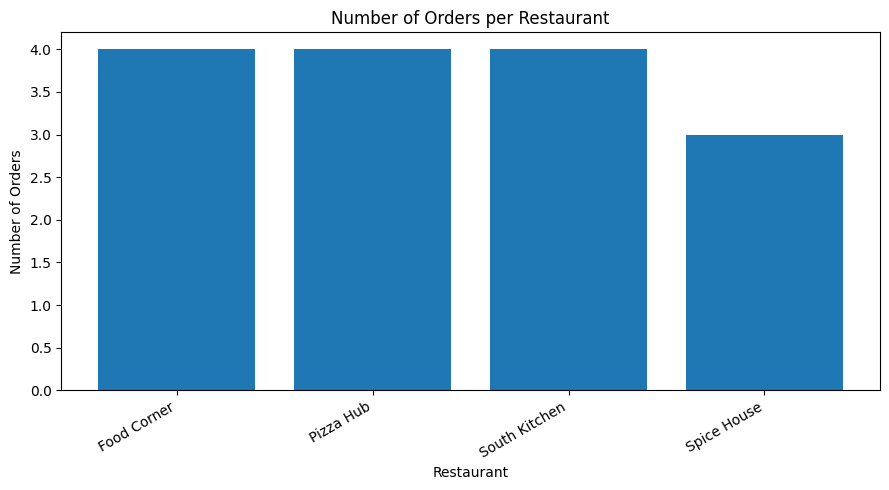

In [ ]:
# Create a bar chart to compare the number of orders per restaurant.
restaurant_orders = df.groupBy("restaurant").count().orderBy("restaurant")
restaurant_pd = restaurant_orders.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(restaurant_pd["restaurant"], restaurant_pd["count"])
plt.xlabel("Restaurant")
plt.ylabel("Number of Orders")
plt.title("Number of Orders per Restaurant")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

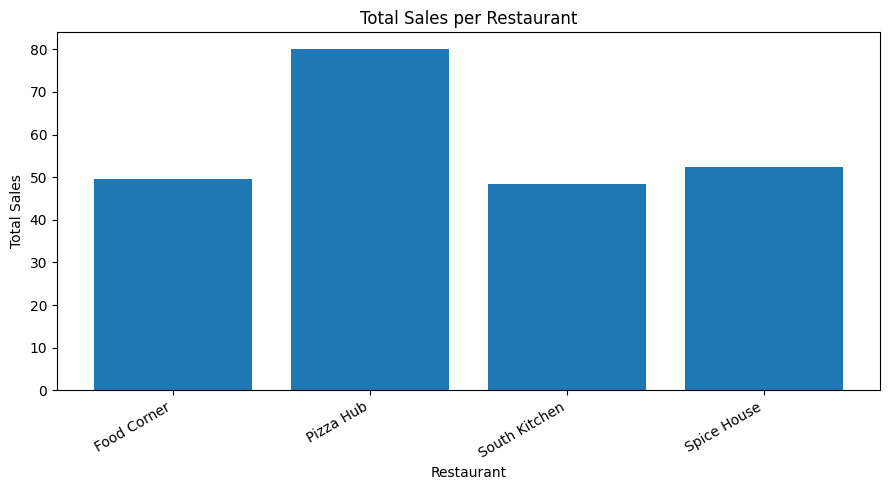

In [ ]:
# Create a bar chart to compare the total sales of each restaurant.
restaurant_sales = df.groupBy("restaurant").agg(
    round(sum("total_value"), 2).alias("total_sales")
).orderBy("restaurant")

sales_pd = restaurant_sales.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(sales_pd["restaurant"], sales_pd["total_sales"])
plt.xlabel("Restaurant")
plt.ylabel("Total Sales")
plt.title("Total Sales per Restaurant")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Part D – Practice Exercises


In [ ]:
# Display customer names, food items and cities.
df.select("customer", "item", "city").show(truncate=False)

+--------+------------+---------+
|customer|item        |city     |
+--------+------------+---------+
|Aarav   |Burger      |Bengaluru|
|Diya    |Pizza       |Mysuru   |
|Rohan   |French Fries|Bengaluru|
|Ananya  |Dosa        |Chennai  |
|Vikram  |Pizza       |Bengaluru|
|Meera   |Idli        |Chennai  |
|Arjun   |Biryani     |Hyderabad|
|Isha    |Burger      |Mysuru   |
|Kabir   |Biryani     |Hyderabad|
|Saanvi  |Dosa        |Bengaluru|
|Rahul   |Pasta       |Chennai  |
|Priya   |Noodles     |Hyderabad|
|Neha    |Sandwich    |Bengaluru|
|Aditya  |Pizza       |Mysuru   |
|Kavya   |Idli        |Chennai  |
+--------+------------+---------+



In [ ]:
# Display all orders placed in Chennai.
df.filter(col("city") == "Chennai").show(truncate=False)

+--------+--------+-------------+-----+--------+----------+-------------+------+-------+-----------+
|order_id|customer|restaurant   |item |quantity|item_price|delivery_time|rating|city   |total_value|
+--------+--------+-------------+-----+--------+----------+-------------+------+-------+-----------+
|O004    |Ananya  |South Kitchen|Dosa |2       |5.5       |25           |5     |Chennai|11.0       |
|O006    |Meera   |South Kitchen|Idli |4       |3.0       |20           |5     |Chennai|12.0       |
|O011    |Rahul   |Pizza Hub    |Pasta|2       |10.0      |32           |5     |Chennai|20.0       |
|O015    |Kavya   |South Kitchen|Idli |3       |3.0       |18           |4     |Chennai|9.0        |
+--------+--------+-------------+-----+--------+----------+-------------+------+-------+-----------+



In [ ]:
# Find orders where the quantity is greater than 2.
df.filter(col("quantity") > 2).show(truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|12.0       |
|O006    |Meera   |South Kitchen|Idli        |4       |3.0       |20           |5     |Chennai  |12.0       |
|O010    |Saanvi  |South Kitchen|Dosa        |3       |5.5       |27           |4     |Bengaluru|16.5       |
|O015    |Kavya   |South Kitchen|Idli        |3       |3.0       |18           |4     |Chennai  |9.0        |
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+



In [ ]:
# Count the total number of orders placed in each city.
df.groupBy("city").count().orderBy(desc("count")).show()

+---------+-----+
|     city|count|
+---------+-----+
|Bengaluru|    5|
|  Chennai|    4|
|Hyderabad|    3|
|   Mysuru|    3|
+---------+-----+



In [ ]:
# Find the most popular food item based on total quantity ordered.
df.groupBy("item").agg(sum("quantity").alias("total_quantity")) \
  .orderBy(desc("total_quantity")).show(1)

+----+--------------+
|item|total_quantity|
+----+--------------+
|Idli|             7|
+----+--------------+
only showing top 1 row


In [ ]:
# Find the restaurant that generated the highest total sales.
df.groupBy("restaurant").agg(round(sum("total_value"), 2).alias("total_sales")) \
  .orderBy(desc("total_sales")).show(1)

+----------+-----------+
|restaurant|total_sales|
+----------+-----------+
| Pizza Hub|       80.0|
+----------+-----------+
only showing top 1 row


In [ ]:
# Display orders where delivery time is greater than 30 minutes.
df.filter(col("delivery_time") > 30).show(truncate=False)

+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant |item   |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+
|O002    |Diya    |Pizza Hub  |Pizza  |1       |15.0      |35           |4     |Mysuru   |15.0       |
|O005    |Vikram  |Pizza Hub  |Pizza  |2       |15.0      |40           |3     |Bengaluru|30.0       |
|O007    |Arjun   |Spice House|Biryani|2       |12.5      |45           |4     |Hyderabad|25.0       |
|O009    |Kabir   |Spice House|Biryani|1       |12.5      |38           |5     |Hyderabad|12.5       |
|O011    |Rahul   |Pizza Hub  |Pasta  |2       |10.0      |32           |5     |Chennai  |20.0       |
|O012    |Priya   |Spice House|Noodles|2       |7.5       |36           |3     |Hyderabad|15.0       |
+--------+--------+-----------+-------+--------+----------+-------------+

In [ ]:
# Calculate the average customer rating for each city.
df.groupBy("city").agg(round(avg("rating"), 2).alias("average_rating")).show()

+---------+--------------+
|     city|average_rating|
+---------+--------------+
|  Chennai|          4.75|
|Bengaluru|           4.0|
|Hyderabad|           4.0|
|   Mysuru|          4.33|
+---------+--------------+



In [ ]:
# Display the three orders with the highest total value.
df.orderBy(desc("total_value")).show(3, truncate=False)

+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant |item   |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+
|O005    |Vikram  |Pizza Hub  |Pizza  |2       |15.0      |40           |3     |Bengaluru|30.0       |
|O007    |Arjun   |Spice House|Biryani|2       |12.5      |45           |4     |Hyderabad|25.0       |
|O011    |Rahul   |Pizza Hub  |Pasta  |2       |10.0      |32           |5     |Chennai  |20.0       |
+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+
only showing top 3 rows


In [ ]:
# Classify orders into High Value and Low Value categories.
df.withColumn(
    "order_category",
    when(col("total_value") > 20, "High Value").otherwise("Low Value")
).select("order_id", "total_value", "order_category").show()

+--------+-----------+--------------+
|order_id|total_value|order_category|
+--------+-----------+--------------+
|    O001|       17.0|     Low Value|
|    O002|       15.0|     Low Value|
|    O003|       12.0|     Low Value|
|    O004|       11.0|     Low Value|
|    O005|       30.0|    High Value|
|    O006|       12.0|     Low Value|
|    O007|       25.0|    High Value|
|    O008|        8.5|     Low Value|
|    O009|       12.5|     Low Value|
|    O010|       16.5|     Low Value|
|    O011|       20.0|     Low Value|
|    O012|       15.0|     Low Value|
|    O013|       12.0|     Low Value|
|    O014|       15.0|     Low Value|
|    O015|        9.0|     Low Value|
+--------+-----------+--------------+



# Conclusion

The Online Food Delivery dataset was analysed using PySpark. Different DataFrame operations and SQL queries were used to understand the data. Restaurant sales, popular food items, delivery time and ratings were analysed. Bar charts were also created to display the results. This project helped me understand PySpark and its use in data analysis.